# 5. Is a smaller file a faster model?

P49 asks for accuracy, size and **CPU latency** (time per photo). Measured with `src/cpu_latency.py`:
one photo at a time, median of 50 runs, on an Apple M2 laptop and on an Intel Xeon (Kaggle).

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # run from the repository root
sys.path.insert(0, "src")
import numpy as np
from IPython.display import Image, display

import ast
def show(path, *names):
    """Print the real source of functions/classes from a file in src/ (read directly, never copied)."""
    src = open(path).read(); lines = src.splitlines(); tree = ast.parse(src)
    nodes = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.ClassDef))}
    for name in names:
        n = nodes[name]; start = n.decorator_list[0].lineno if n.decorator_list else n.lineno
        print(f"# ---- {path}, lines {start}-{n.end_lineno}")
        print("\n".join(lines[start - 1:n.end_lineno])); print()

def show_lines(path, start_text, end_text):
    """Print a block of a script, from the line containing start_text to the line containing end_text."""
    lines = open(path).read().splitlines()
    i = next(k for k, l in enumerate(lines) if start_text in l)
    j = next(k for k, l in enumerate(lines[i + 1:], i + 1) if end_text in l)
    print(f"# ---- {path}, lines {i + 1}-{j + 1}"); print("\n".join(lines[i:j + 1]))

In [2]:
show("src/cpu_latency.py", "pruned_deit_s", "bench")

# ---- src/cpu_latency.py, lines 30-36
def pruned_deit_s(hidden=1162):
    """Route C's shapes: DeiT-S with every MLP hidden layer cut from 1536 to 1162."""
    m = timm.create_model("deit_small_patch16_224", pretrained=False)
    for blk in m.blocks:
        d = blk.mlp.fc1.in_features
        blk.mlp.fc1, blk.mlp.fc2 = nn.Linear(d, hidden), nn.Linear(hidden, d)
    return m

# ---- src/cpu_latency.py, lines 48-57
def bench(model, threads):
    torch.set_num_threads(threads)
    x = torch.randn(1, 3, 224, 224)
    with torch.inference_mode():
        for _ in range(a.warmup): model(x)
        ts = []
        for _ in range(a.runs):
            t = time.perf_counter(); model(x); ts.append((time.perf_counter() - t) * 1e3)
    q = statistics.quantiles(ts, n=4)
    return {"median_ms": statistics.median(ts), "q1_ms": q[0], "q3_ms": q[2]}



In [3]:
M2 = json.load(open("evidence/latency/cpu_latency.json"))
X86 = json.load(open("evidence/rescore/cpu_latency_x86.json"))
def table(J, name):
    print(f"--- {name} ({J['meta']['machine'][:40]})")
    print(f"{'network':<34}{'kind':>14}{'threads':>9}{'ms':>9}")
    for r in J["rows"]:
        print(f"{r['model']:<34}{r['kind']:>14}{r['threads']:>9}{r['median_ms']:>9.1f}")
    print()
table(M2, "Apple M2"); table(X86, "Intel Xeon")

--- Apple M2 (macOS-26.5.1-arm64-arm-64bit-Mach-O)
network                                     kind  threads       ms
DeiT-S baseline (FP32, 88.2 MB)             fp32        1     23.2
DeiT-S baseline (FP32, 88.2 MB)             fp32        4     17.8
DeiT-S baseline (FP32, 88.2 MB)     int8-dynamic        1    105.5
DeiT-S baseline (FP32, 88.2 MB)     int8-dynamic        4    101.7
A / B: decode to DeiT-S                     fp32        1     23.2
A / B: decode to DeiT-S                     fp32        4     17.8
A / B: decode to DeiT-S             int8-dynamic        1    105.5
A / B: decode to DeiT-S             int8-dynamic        4    101.7
C: pruned DeiT-S (MLP 1162)                 fp32        1     21.0
C: pruned DeiT-S (MLP 1162)                 fp32        4     16.1
C: pruned DeiT-S (MLP 1162)         int8-dynamic        1     89.8
C: pruned DeiT-S (MLP 1162)         int8-dynamic        4     88.6
D: DeiT-Tiny                                fp32        1      9.7
D: DeiT-Tin

**Reading it:** routes A and B (3-bit and ternary) are nine times smaller than the original but run at the
same speed: there is no fast CPU routine for 3-bit or ternary weights, so they are expanded back to normal numbers
when loaded. Pruning (C) gains about 10%. Only the distilled DeiT-Tiny (D) is much faster: 2.2 times on the M2 and
2.4 times on Intel (32-bit, 4 threads). The 8-bit numbers differ by machine: slower than 32-bit on the M2, faster on Intel.

In [4]:
ms = lambda J, m: [r["median_ms"] for r in J["rows"] if r["model"].startswith(m) and r["kind"] == "fp32" and r["threads"] == 4][0]
for J, n in ((M2, "M2"), (X86, "Intel")):
    print(f"{n}: A/B {ms(J, 'A / B'):.1f} ms, D {ms(J, 'D:'):.1f} ms  ->  D is {ms(J, 'A / B')/ms(J, 'D:'):.2f}x faster")

M2: A/B 17.8 ms, D 8.0 ms  ->  D is 2.23x faster
Intel: A/B 71.4 ms, D 29.9 ms  ->  D is 2.38x faster


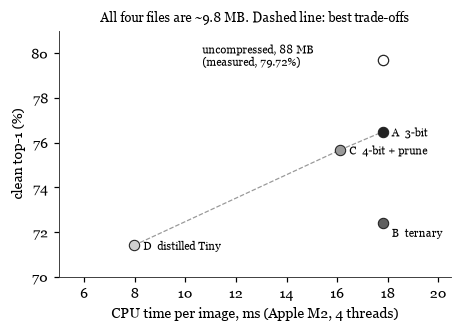

In [5]:
display(Image("proposal/figs/png/fig6_pareto.png", width=520))